# Занятие 10. Метрики качества ML-моделей
**Команда 3 · Вариант 9 — рекомендации товаров в интернет-магазине**

Модель для каждого пользователя формирует топ-10 товаров для блока «Вам может понравиться». Нужно оценить качество выдачи и решить, готова ли модель к запуску.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


## Шаг 1. Загрузка и обзор данных

In [2]:
df = pd.read_csv('metrics_datasets/variant_9_recsys.csv')
df['recommended_items'] = df['recommended_items'].apply(lambda s: [int(x) for x in s.split(';')])
df['relevant_items'] = df['relevant_items'].apply(lambda s: [int(x) for x in s.split(';')])

print('Пользователей:', len(df))
print('Длина выдачи:', df['recommended_items'].apply(len).unique())
print('Релевантных товаров на пользователя:')
print(df['relevant_items'].apply(len).value_counts().sort_index())
n_items = len(set(sum(df['recommended_items'].tolist(), [])) | set(sum(df['relevant_items'].tolist(), [])))
print('Уникальных товаров в каталоге (по данным):', n_items)
df.head()

Пользователей: 120
Длина выдачи: [10]
Релевантных товаров на пользователя:
relevant_items
1    47
2    39
3    34
Name: count, dtype: int64
Уникальных товаров в каталоге (по данным): 100


,user_id,recommended_items,relevant_items
0,1,"[3, 36, 27, 64, 47, 43, 23, 5, 11, 31]","[85, 68]"
1,2,"[61, 93, 14, 44, 48, 25, 94, 45, 75, 68]","[72, 94]"
2,3,"[58, 10, 33, 49, 20, 92, 82, 79, 9, 72]",[46]
3,4,"[32, 38, 86, 94, 39, 50, 76, 57, 27, 8]","[8, 55]"
4,5,"[65, 71, 64, 60, 87, 11, 55, 88, 7, 15]","[93, 76]"


У каждого пользователя всего 1–3 релевантных товара при каталоге из 100 позиций. Поэтому даже идеальная модель получила бы Precision@10 не выше 0.1–0.3 у конкретного пользователя (в среднем по выборке максимум ≈ 0.19). Значит, абсолютные значения метрик будут небольшими, и их нужно сравнивать со случайной выдачей, а не с единицей.

## Шаг 2. Функции метрик

In [3]:
def precision_at_k(rec, rel, k):
    return len(set(rec[:k]) & set(rel)) / k

def recall_at_k(rec, rel, k):
    return len(set(rec[:k]) & set(rel)) / len(rel) if rel else 0

def average_precision(rec, rel, k):
    hits, score = 0, 0.0
    for i, item in enumerate(rec[:k], start=1):
        if item in rel:
            hits += 1
            score += hits / i
    return score / min(len(rel), k) if rel else 0

def reciprocal_rank(rec, rel):
    for i, item in enumerate(rec, start=1):
        if item in rel:
            return 1 / i
    return 0

def ndcg_at_k(rec, rel, k):
    dcg = sum(1/np.log2(i+1) for i, item in enumerate(rec[:k], start=1) if item in rel)
    idcg = sum(1/np.log2(i+1) for i in range(1, min(len(rel), k)+1))
    return dcg / idcg if idcg > 0 else 0

def hit_at_k(rec, rel, k):
    return int(len(set(rec[:k]) & set(rel)) > 0)

## Шаг 3. Расчёт метрик по всем пользователям

In [4]:
K = 10
R, L = 'recommended_items', 'relevant_items'
df['precision_k'] = df.apply(lambda r: precision_at_k(r[R], r[L], K), axis=1)
df['recall_k'] = df.apply(lambda r: recall_at_k(r[R], r[L], K), axis=1)
df['ap'] = df.apply(lambda r: average_precision(r[R], r[L], K), axis=1)
df['rr'] = df.apply(lambda r: reciprocal_rank(r[R], r[L]), axis=1)
df['ndcg'] = df.apply(lambda r: ndcg_at_k(r[R], r[L], K), axis=1)
df['hit'] = df.apply(lambda r: hit_at_k(r[R], r[L], K), axis=1)

MAP, MRR, mean_ndcg = df['ap'].mean(), df['rr'].mean(), df['ndcg'].mean()
print(f"Precision@{K}={df['precision_k'].mean():.3f}, Recall@{K}={df['recall_k'].mean():.3f}")
print(f"MAP={MAP:.3f}, MRR={MRR:.3f}, NDCG@{K}={mean_ndcg:.3f}")
print(f"HitRate@{K} (доля пользователей хотя бы с 1 попаданием) = {df['hit'].mean():.3f}")
for k in [1, 3, 5]:
    print(f"HitRate@{k} = {df.apply(lambda r: hit_at_k(r[R], r[L], k), axis=1).mean():.3f}")

Precision@10=0.015, Recall@10=0.078
MAP=0.021, MRR=0.042, NDCG@10=0.041
HitRate@10 (доля пользователей хотя бы с 1 попаданием) = 0.150


### Сравнение со случайной выдачей (baseline)
Чтобы понять, хороши ли такие числа, сравним модель со случайными 10 товарами из каталога (усреднение по 200 прогонам).

In [5]:
rng = np.random.default_rng(42)
catalog = np.arange(1, n_items + 1)
rows = [] # 200 прогонов случайной выдачи
for _ in range(200):
    rand = [list(rng.choice(catalog, K, replace=False)) for _ in range(len(df))]
    rows.append({
        'Precision@10': np.mean([precision_at_k(r, l, K) for r, l in zip(rand, df[L])]),
        'Recall@10': np.mean([recall_at_k(r, l, K) for r, l in zip(rand, df[L])]),
        'MAP': np.mean([average_precision(r, l, K) for r, l in zip(rand, df[L])]),
        'MRR': np.mean([reciprocal_rank(r, l) for r, l in zip(rand, df[L])]),
        'NDCG@10': np.mean([ndcg_at_k(r, l, K) for r, l in zip(rand, df[L])]),
        'HitRate@10': np.mean([hit_at_k(r, l, K) for r, l in zip(rand, df[L])]),
    })
baseline = pd.DataFrame(rows).mean()
model = pd.Series({'Precision@10': df['precision_k'].mean(), 'Recall@10': df['recall_k'].mean(),
                   'MAP': MAP, 'MRR': MRR, 'NDCG@10': mean_ndcg, 'HitRate@10': df['hit'].mean()})
comparison = pd.DataFrame({'Модель': model, 'Случайная выдача': baseline}).round(3)

# Насколько различие модели и случайной выдачи устойчиво: доля случайных прогонов, где NDCG@10 не выше, чем у модели
rand_ndcg = pd.DataFrame(rows)['NDCG@10']
print(f"Доля случайных прогонов с NDCG@10 ≤ модели: {(rand_ndcg <= mean_ndcg).mean():.0%}")
comparison

,Модель,Случайная выдача
Precision@10,0.015,0.019
Recall@10,0.078,0.102
MAP,0.021,0.030
MRR,0.042,0.055
NDCG@10,0.041,0.055
HitRate@10,0.150,0.180


## Шаг 4. Графики

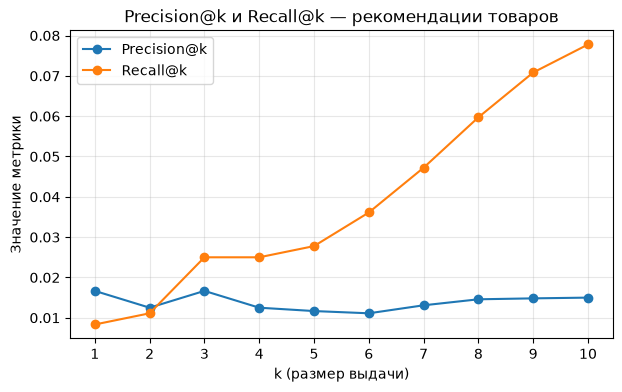

In [6]:
ks = range(1, K+1)
prec_by_k = [df.apply(lambda r: precision_at_k(r[R], r[L], k), axis=1).mean() for k in ks]
rec_by_k = [df.apply(lambda r: recall_at_k(r[R], r[L], k), axis=1).mean() for k in ks]

plt.figure(figsize=(7,4))
plt.plot(ks, prec_by_k, marker='o', label='Precision@k')
plt.plot(ks, rec_by_k, marker='o', label='Recall@k')
plt.xlabel('k (размер выдачи)'); plt.ylabel('Значение метрики')
plt.title('Precision@k и Recall@k — рекомендации товаров')
plt.xticks(list(ks)); plt.grid(alpha=0.3); plt.legend(); plt.show()

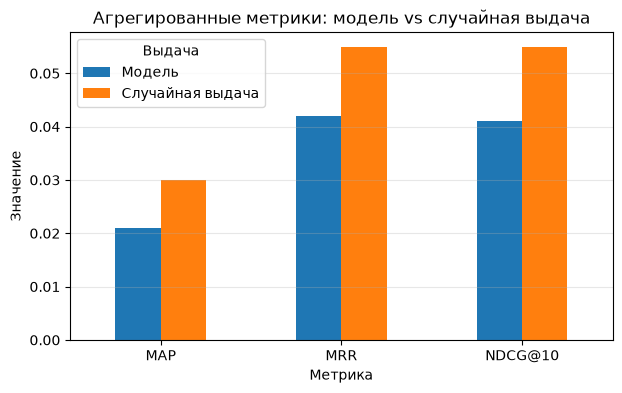

In [7]:
ax = comparison.loc[['MAP', 'MRR', 'NDCG@10']].plot.bar(figsize=(7,4), rot=0)
ax.set_title('Агрегированные метрики: модель vs случайная выдача')
ax.set_xlabel('Метрика'); ax.set_ylabel('Значение'); ax.grid(axis='y', alpha=0.3)
plt.legend(title='Выдача'); plt.show()

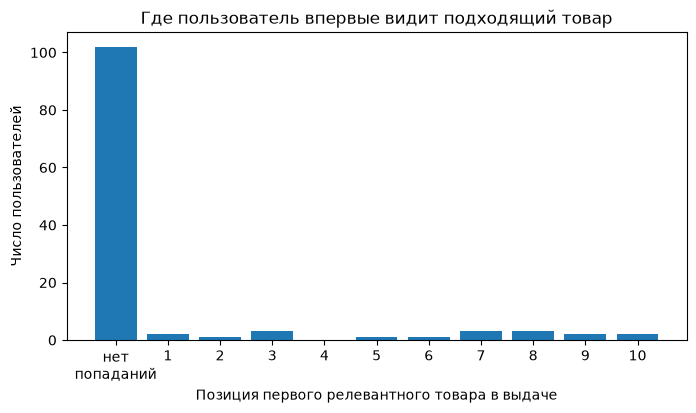

In [8]:
first_hit = df.apply(lambda r: next((i for i, it in enumerate(r[R], 1) if it in r[L]), 0), axis=1)
counts = first_hit.value_counts().reindex(range(0, K+1), fill_value=0)
labels = ['нет\nпопаданий'] + [str(i) for i in range(1, K+1)]
plt.figure(figsize=(8,4))
plt.bar(labels, counts.values)
plt.xlabel('Позиция первого релевантного товара в выдаче'); plt.ylabel('Число пользователей')
plt.title('Где пользователь впервые видит подходящий товар')
plt.show()

## Шаг 5. Интерпретация в терминах продукта

**HitRate@10 = 0.15.** Только 18 из 120 покупателей увидят в блоке рекомендаций хотя бы один товар, который им действительно нужен. Для остальных 85% блок — бесполезное место на странице, которое не приводит ни к клику, ни к покупке.

**Precision@10 = 0.015.** Из 10 показанных карточек в среднем подходит лишь 0.15 карточки, то есть одно попадание примерно на 7 показов блока. Пользователь, раз за разом не находя в блоке ничего интересного, привыкает его игнорировать, а магазин впустую тратит место на витрине.

**Recall@10 = 0.078.** Модель находит менее 8% товаров, которые пользователь действительно хотел бы купить. Потенциальная дополнительная выручка от кросс-продаж почти не реализуется.

**MRR = 0.042, MAP = 0.021.** Даже когда попадание есть, подходящий товар чаще всего стоит в конце выдачи: у 11 из 18 пользователей с попаданием первый релевантный товар находится на позициях 6–10, в топ-3 — только у 6 (HitRate@1 ≈ 1.7%, HitRate@3 = 5%). Нижние карточки видят реже всего, особенно на мобильном, где без прокрутки видны только первые, поэтому для сценария «увидел — кликнул — купил» это критично.

**NDCG@10 = 0.041.** Порядок выдачи далёк от идеального: релевантные товары не подняты наверх, а разбросаны по списку.

**Главное — сравнение со случайной выдачей.** По всем метрикам модель немного уступает случайному набору из 10 товаров (например, NDCG@10 0.041 против 0.055). На выборке из 120 пользователей эта разница не является надёжной: примерно в каждом седьмом случайном прогоне (≈13%, см. расчёт выше) NDCG@10 оказывается не выше, чем у модели. Корректный вывод — модель не лучше случайной выдачи, то есть пока не выучила предпочтения покупателей.

### Приоритетная метрика
Для блока рекомендаций в интернет-магазине приоритетна **NDCG@10**, а также Precision@k и HitRate@k при малых k. Внимание пользователя сосредоточено на первых карточках, и именно они приносят клики и покупки, поэтому важно не просто попасть в интересы, а поставить подходящий товар как можно выше. NDCG учитывает позицию каждого попадания, а MAP при 1–3 релевантных товарах на пользователя ведёт себя почти как MRR и даёт меньше дополнительной информации. Recall здесь вторичен: задача блока — не показать покупателю всё, что ему может понравиться, а дать несколько точных предложений.

### Сильные стороны
- Модель стабильно отдаёт полную выдачу из 10 товаров каждому пользователю, без пустых списков и дублей, то есть техническая часть пайплайна работает.
- Есть 18 пользователей с попаданием, из них 6 — в топ-3; их можно изучить, чтобы понять, на каких сигналах модель срабатывает.

### Слабые стороны
- Качество на уровне случайной выдачи по всем метрикам.
- Попадания в первые позиции единичны — худший вариант для UX.
- 85% пользователей не получают ни одного релевантного товара.

## Заключение

**Модель требует доработки и не готова к запуску.** Её выдача по качеству не лучше случайного набора товаров, поэтому запуск не даст прироста конверсии и среднего чека, а займёт место на витрине и может снизить доверие к блоку рекомендаций.

Что нужно улучшить:
1. **Сравнивать с простыми baseline** — популярные товары, «с этим товаром покупают». Новая модель должна обгонять их, а не только случайную выдачу.
2. **Использовать больше сигналов о пользователе** — история просмотров, корзина, категории покупок, а не только покупки (у каждого пользователя всего 1–3 релевантных товара — по ним одним предпочтения не выучить).
3. **Перейти к моделям коллаборативной фильтрации / факторизации** (ALS, item2item) и ранжированию с оптимизацией NDCG.
4. **Отдельно решать холодный старт** для пользователей с короткой историей.
5. **Оценить на большей выборке** пользователей (120 мало для надёжных выводов), сначала офлайн против baseline, затем — A/B-тест по CTR блока и доле покупок из рекомендаций.